In [1]:
include("config.jl")
include("generate_neutrino_flux.jl");


In [5]:
using CairoMakie   
using Statistics


In [2]:
# Energy bins uniform in 1/E (∝ L/E for a fixed path), 1–50 GeV
minEnergy     = 1.0      # [GeV]
maxEnergy     = 50.0     # [GeV]
numEnergyBins = 100

invE_edges   = range(1 / maxEnergy, 1 / minEnergy, numEnergyBins + 1)   # Δ(1/E) ≈ 0.0098 GeV⁻¹
invE_centers = (invE_edges[1:end-1] .+ invE_edges[2:end]) ./ 2
energies     = reverse(1 ./ invE_centers)                               # ascending [GeV]

# cos(θ): 75 linear bins
numAngleBins = 75
cosθs = range(-1, 1, numAngleBins + 1)
cosθs = (cosθs[1:end-1] .+ cosθs[2:end]) ./ 2;

# ϕ: 360 bins of 1°
numAzimuthBins = 360
ϕs = range(0.0, 360.0, numAzimuthBins + 1)
ϕs = (ϕs[1:end-1] .+ ϕs[2:end]) ./ 2;       # 0.5°, 1.5°, …, 359.5°


In [3]:
nuflux = produce_neutrino_flux(Dict{String, Any}(
    "model"                => :Cheng,          
    "angles_separation"    => :variable_ϕ,
    "bin_centers_arrays"   => (energies, cosθs, ϕs)
))

E    = nuflux["Energies"]     
cosθ = nuflux["cosθs"]         
ϕs   = nuflux["ϕs"]            

# first azimuth bin: 0°–30° -> esto tenes que varias para obtener distintos phi
iϕ = 1                         

flux_νe  = nuflux["Nue_flux"][:, :, iϕ]
flux_νμ  = nuflux["NuMu_flux"][:, :, iϕ]
flux_aνe = nuflux["AntiNue_flux"][:, :, iϕ]
flux_aνμ = nuflux["AntiNuMu_flux"][:, :, iϕ];


solar_activity => minimum
location => orca
model => Cheng
bin_centers_arrays => ([1.0049241282283188, 1.0149193139145438, 1.0251153254741159, 1.0355182768975872, 1.046134532900931, 1.056970721911003, 1.0680337498664958, 1.0793308148947653, 1.0908694229300753, 1.1026574043444701, 1.1147029316687103, 1.1270145384875465, 1.1396011396011396, 1.1524720525527257, 1.1656370206317752, 1.1791062374719963, 1.1928903733746867, 1.2070006035003018, 1.2214486380847687, 1.2362467548522684, 1.2514078338130397, 1.2669453946534905, 1.2828736369467608, 1.2992074834351044, 1.3159626266614028, 1.3331555792560992, 1.3508037282182899, 1.3689253935660506, 1.3875398917718884, 1.4066676044450697, 1.4263300527742118, 1.4465499783017504, 1.467351430667645, 1.4887598630340926, 1.5108022359873092, 1.5335071308081583, 1.5569048731122528, 1.5810276679841895, 1.6059097478721696, 1.6315875346712352, 1.6580998176090203, 1.6854879487611663, 1.713796058269066, 1.743071291615827, 1.7733640716439083, 1.8047283883775491, 1.8

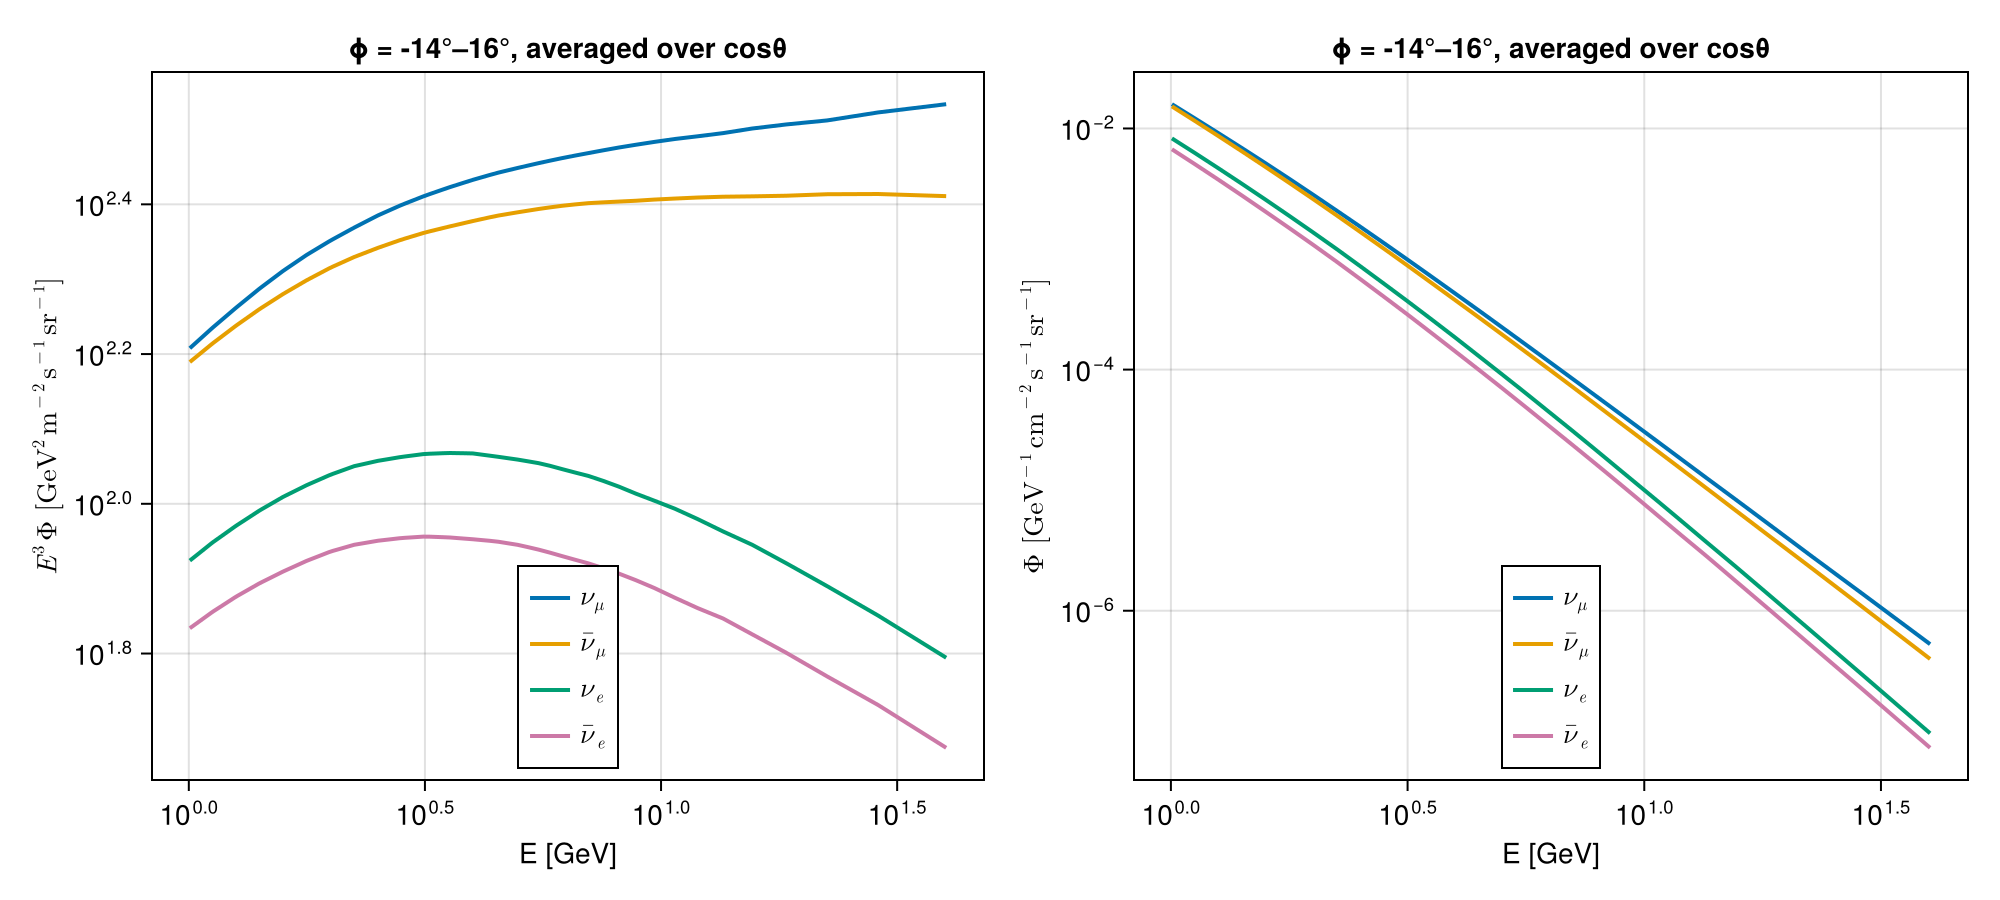

In [6]:
flux_list = [flux_νμ, flux_aνμ, flux_νe, flux_aνe]
keys_err  = ["NuMu_flux_err", "AntiNuMu_flux_err", "Nue_flux_err", "AntiNue_flux_err"]
flux_err_list = [haskey(nuflux, k) ? nuflux[k][:, :, iϕ] : nothing for k in keys_err]
labels = [L"\nu_\mu", L"\bar\nu_\mu", L"\nu_e", L"\bar\nu_e"]
colors = Makie.wong_colors()[1:4]

ϕ_lo, ϕ_hi = round(Int, ϕs[iϕ] - 15), round(Int, ϕs[iϕ] + 15)
ttl = "ϕ = $(ϕ_lo)°–$(ϕ_hi)°, averaged over cosθ"

fig2 = Figure(size = (1000, 450))

ax1 = Axis(fig2[1, 1];
           xscale = log10, yscale = log10,
           xlabel = "E [GeV]",
           ylabel = L"E^3\,\Phi\ [\mathrm{GeV^{2}\,m^{-2}\,s^{-1}\,sr^{-1}}]",
           title  = ttl)
for (label, flux, err, c) in zip(labels, flux_list, flux_err_list, colors)
    φ = vec(mean(flux, dims = 2))
    if err !== nothing
        Δφ = vec(mean(err, dims = 2))
        band!(ax1, E, E .^ 3 .* (φ .- Δφ), E .^ 3 .* (φ .+ Δφ); color = (c, 0.25))
    end
    lines!(ax1, E, E .^ 3 .* φ; label = label, linewidth = 2, color = c)
end
axislegend(ax1; position = :cb)

ax2 = Axis(fig2[1, 2];
           xscale = log10, yscale = log10,
           xlabel = "E [GeV]",
           ylabel = L"\Phi\ [\mathrm{GeV^{-1}\,cm^{-2}\,s^{-1}\,sr^{-1}}]",
           title  = ttl)
for (label, flux, c) in zip(labels, flux_list, colors)
    φ = vec(mean(flux, dims = 2)) ./ 10000.
    lines!(ax2, E, φ; label = label, linewidth = 2, color = c)
end
axislegend(ax2; position = :cb)

fig2